# Laboratory 6 — Human Activity Recognition, Part One

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 6 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | *Ruth Benedicta Susanto* |
| **Student ID** | *6710755239* |
| **Section** | *750001* |

## What you will do today

Build the file the rest of the term will reuse: **`har_features.csv`** — a labelled feature matrix
for three activities (*still · walking · running*) from a 3-axis accelerometer. The recipe is the
lecture's slide 13: **stream → windows → questions → matrix.**

**Deliverables (due before week 7, pushed to your GitHub repository):**
1. **`har_features.csv`** — ~177 rows × 27 features + label — THE file weeks 7, 8, 9 and 13 will open
2. **The separation scatter** — slide 14's figure from your own data, three colours, axes labelled
3. **One insight** — which single feature separates best, and which pair of activities stays hardest — with numbers

> **The week's honesty rule:** overlapping windows share samples — when models arrive in week 8,
> we will split train/test **by recording, never by window**. Remember you read it here first.


## Setup — run first, do not edit


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

plt.rcParams['figure.figsize'] = (12, 3.5)
plt.rcParams['axes.grid'] = True
print("NumPy", np.__version__, "· Pandas", pd.__version__)

NumPy 2.4.6 · Pandas 2.2.3


### The data — your phone, or the provided generator

**Preferred:** record three 60 s sessions with **Sensor Logger** or **phyphox** (50 Hz), export CSV,
rename to `still.csv`, `walking.csv`, `running.csv` (columns `time_s, ax_g, ay_g, az_g`) and upload
them via the Files pane. **Fallback:** the cell below synthesises the same three sessions —
deterministic, so everyone's numbers match. It uses whichever it finds.


   still: 3000 samples (synthesised)
 walking: 3000 samples (synthesised)
 running: 3000 samples (synthesised)


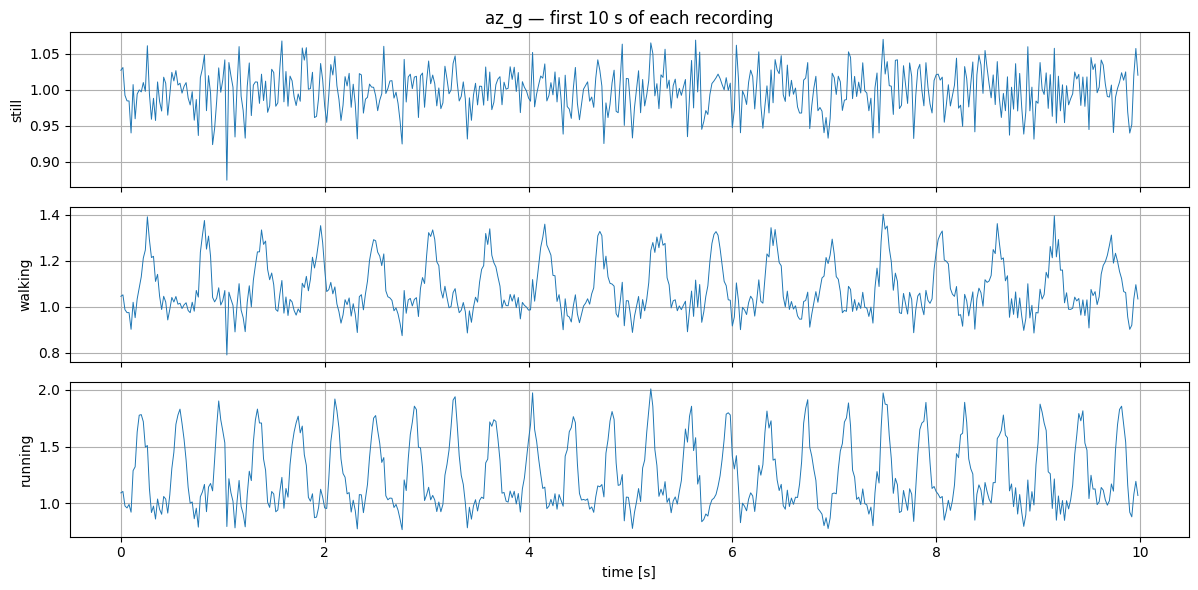

In [2]:
# --- Load or synthesise the three recordings (run once, do not edit) ----------
FS = 50
DUR = 60

def _synth(activity, rng):
    t = np.arange(0, DUR, 1 / FS)
    n = t.size
    if activity == "still":
        return pd.DataFrame({
            "time_s": t,
            "ax_g": 0.02 * rng.standard_normal(n),
            "ay_g": 0.02 * rng.standard_normal(n),
            "az_g": 1.0 + 0.03 * rng.standard_normal(n),
        })
    if activity == "walking":                      # Labs 4-5's walker, back again
        swing = np.sin(2 * np.pi * 0.9 * t)
        return pd.DataFrame({
            "time_s": t,
            "ax_g": 0.50 * swing + 0.20 * rng.standard_normal(n),
            "ay_g": 0.35 * swing + 0.20 * rng.standard_normal(n),
            "az_g": 1.0 + 0.30 * np.abs(np.sin(np.pi * 1.8 * t)) ** 8
                     + 0.05 * rng.standard_normal(n),
        })
    swing = np.sin(2 * np.pi * 1.3 * t)            # running: faster, harder
    return pd.DataFrame({
        "time_s": t,
        "ax_g": 0.90 * swing + 0.30 * rng.standard_normal(n),
        "ay_g": 0.60 * swing + 0.30 * rng.standard_normal(n),
        "az_g": 1.0 + 0.80 * np.abs(np.sin(np.pi * 2.6 * t)) ** 6
                 + 0.10 * rng.standard_normal(n),
    })

recordings = {}
for act in ("still", "walking", "running"):
    try:
        recordings[act] = pd.read_csv(f"{act}.csv")[["time_s", "ax_g", "ay_g", "az_g"]]
        src = "your file"
    except Exception:
        recordings[act] = _synth(act, np.random.default_rng(240))
        src = "synthesised"
    print(f"{act:>8}: {len(recordings[act])} samples ({src})")

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax_, (act, df) in zip(axes, recordings.items()):
    ax_.plot(df.time_s[:10 * FS], df.az_g[:10 * FS], linewidth=0.7)
    ax_.set_ylabel(act)
axes[0].set_title("az_g — first 10 s of each recording")
axes[-1].set_xlabel("time [s]")
plt.tight_layout(); plt.show()

---
## Mission 1 — The adapter: write `sliding_window` yourself

The one function that bridges signals and machine learning is worth owning.
**Window = 100 samples (2 s), step = 50 (50% overlap).**


In [3]:
def sliding_window(x, win=100, step=50):
    """Return a list of 1-D arrays: consecutive windows of length `win`, every `step` samples.
    Drop any leftover tail shorter than `win`."""
    # TODO (1.1): a list comprehension is enough —
    #   starts run 0, step, 2*step, ... while start + win <= len(x)
    #   each window is x[start : start + win]
    return [x[start : start + win] for start in range(0, len(x) - win + 1, step)]


wins = sliding_window(recordings["walking"]["az_g"].values)
if wins is None:
    print("sliding_window not filled in yet")
else:
    print(f"windows: {len(wins)}   first window length: {len(wins[0])}")
    print("expected: 59 windows of 100 samples from 3,000 samples (check the arithmetic!)")

windows: 59   first window length: 100
expected: 59 windows of 100 samples from 3,000 samples (check the arithmetic!)


**Checkpoint:** 3,000 samples, window 100, step 50 → starts at 0, 50, …, 2,900 = **59 windows**.
If you got 60, your last window ran off the end; if 30, you forgot the overlap.


---
## Mission 2 — The nine questions

Five statistical (week 4) + four spectral (week 5). One rule from the lecture:
**Hann before every FFT** — and spectral features are computed on the *demeaned* window
(gravity's DC would otherwise drown everything — week 5's bin-0 lesson).


In [4]:
def spectrum(x, fs):
    """(f, mag) with a Hann window applied first — Lab 5's function, upgraded per the lecture."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    # TODO (2.1): apply the Hann window, then week 5's three lines
    x = x * np.hanning(len(x))
    mag = np.abs(np.fft.rfft(x)) / len(x)
    f   = np.fft.rfftfreq(len(x), 1/fs)
    return f, mag


def stat_features(w):
    """The five statistical questions -> dict."""
    w = np.asarray(w, dtype=float)
    d = w - w.mean()
    # TODO (2.2): fill the five values (zcr = zero-crossing rate per second at FS = 50;
    #   peaks: find_peaks on d with prominence=d.std(), distance=FS//4)
    FS = 50
    duration = len(w) / FS
    peaks, _ = find_peaks(d, prominence=d.std(), distance=FS//4)

    return {
        "mean": np.mean(w),
        "std": np.std(w),
        "rng": np.max(w) - np.min(w),
        "zcr": np.sum(np.diff(np.sign(d)) != 0) / duration,
        "peak_rate": len(peaks) / duration,
    }


def spec_features(w, fs=50):
    """The four spectral questions -> dict."""
    out = spectrum(w, fs)
    if out is None:
        return {"domfreq": None, "bandE": None, "centroid": None, "entropy": None}
    f, mag = out
    p = mag ** 2
    p = p / (p.sum() + 1e-12)               # power distribution over frequencies
    band = (f >= 0.5) & (f <= 3.0)          # the human-gait band — physiology as a column
    return {
        # TODO (2.3): fill the four values
        "domfreq": f[mag[1:].argmax() + 1],
        "bandE": p[band].sum(),
        "centroid": np.sum(f * p),
        "entropy": -np.sum(p * np.log2(p + 1e-12)),
    }


w_test = recordings["walking"]["az_g"].values[:100]
sf, pf = stat_features(w_test), spec_features(w_test)
if None in sf.values() or None in pf.values():
    print("Mission 2 not finished:", {**sf, **pf})
else:
    print("statistical:", {k: round(v, 3) for k, v in sf.items()})
    print("spectral   :", {k: round(v, 3) for k, v in pf.items()})
    print("sanity: domfreq reads 2.0 — the true cadence is 1.8, but a 2 s window has")
    print("Δf = 0.5 Hz, so 1.8 lands on the nearest bin. Week 5's resolution limit, biting for real!")

statistical: {'mean': np.float64(1.083), 'std': np.float64(0.119), 'rng': np.float64(0.599), 'zcr': np.float64(7.5), 'peak_rate': 2.0}
spectral   : {'domfreq': np.float64(2.0), 'bandE': np.float64(0.541), 'centroid': np.float64(5.412), 'entropy': np.float64(3.842)}
sanity: domfreq reads 2.0 — the true cadence is 1.8, but a 2 s window has
Δf = 0.5 Hz, so 1.8 lands on the nearest bin. Week 5's resolution limit, biting for real!


**Q1 — read your own numbers:** for this walking window, which of the nine values would you
expect to *change most* if the subject started running — and why? *(Answer before Mission 4 shows you.)*

If the subject changes from walking to running, I expect std to increase the most clearly among the time-domain features because running produces stronger acceleration variation. In the supplied synthetic data, the mean az_std rises from approximately 0.119 g (walking) to 0.302 g (running). The dominant frequency also rises from approximately 2.0 Hz to 2.5 Hz, reflecting the faster activity. The standard deviation is especially useful because it measures signal intensity without relying on a meaningful rhythm being present.


---
## Mission 3 — Stack the matrix

Every window × every axis × all nine questions → one row per window, 27 features + the label.
The assembly is written for you — it only runs once Missions 1–2 work.


In [5]:
def features_of_window(idx, dfs):
    """One row: the nine questions asked of each axis of window idx."""
    row = {}
    for axis in ("ax_g", "ay_g", "az_g"):
        w = dfs[axis][idx]
        for k, v in {**stat_features(w), **spec_features(w)}.items():
            row[f"{axis[:2]}_{k}"] = v
    return row


ready = (sliding_window(np.arange(300)) is not None
         and spectrum(np.arange(100.0), 50) is not None
         and None not in stat_features(np.arange(100.0)).values())
if not ready:
    print("finish Missions 1-2 first")
else:
    rows = []
    for act, df in recordings.items():
        dfs = {a: sliding_window(df[a].values) for a in ("ax_g", "ay_g", "az_g")}
        for i in range(len(dfs["az_g"])):
            rows.append(features_of_window(i, dfs) | {"label": act})
    har = pd.DataFrame(rows)
    har.to_csv("har_features.csv", index=False)
    print(f"har_features.csv written: {har.shape[0]} rows x {har.shape[1]} columns")
    print(har.groupby("label")[["az_std", "az_domfreq"]].mean().round(3))

har_features.csv written: 177 rows x 28 columns
         az_std  az_domfreq
label                      
running   0.302       2.500
still     0.030      12.585
walking   0.115       1.992


**Checkpoint:** ~177 rows × 28 columns (27 features + label). Read the summary table closely:

- `az_std` orders perfectly: still < walking < running — one column, whole story
- `az_domfreq`: walking ≈ 2.0, running ≈ 2.5 — but **still shows nonsense** (~12 Hz): a window with
  no rhythm has no meaningful dominant frequency; the argmax just lands on noise. That is not a bug —
  and `az_entropy` (high for still) is exactly the feature that CATCHES it. Features cover for each other.


---
## Mission 4 — Deliverable 2: the separation scatter

Slide 14, drawn from **your** matrix: `az_std` on x, `az_domfreq` on y, one colour per activity.


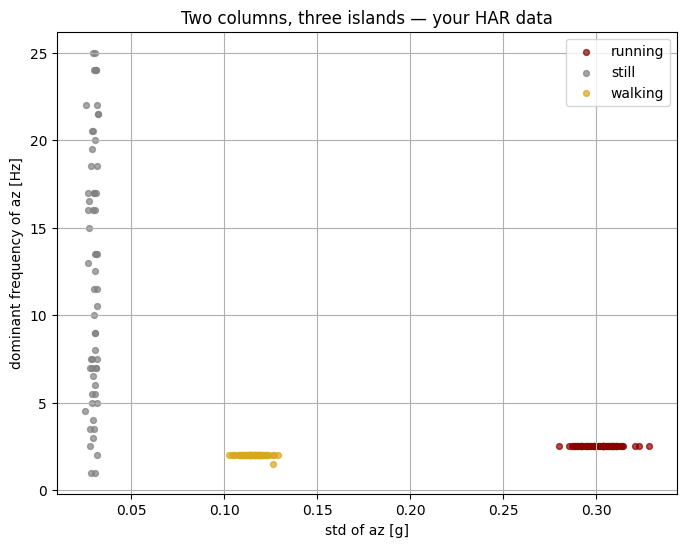

Week 8's classifier will just draw two lines on this picture. That is the whole trick.


In [6]:
try:
    har
    _has = True
except NameError:
    _has = False

if not _has:
    print("finish Mission 3 first")
else:
    colours = {"still": "grey", "walking": "goldenrod", "running": "darkred"}
    plt.figure(figsize=(8, 6))
    for act, grp in har.groupby("label"):
        plt.scatter(grp.az_std, grp.az_domfreq, s=18, alpha=0.7,
                    color=colours[act], label=act)
    plt.xlabel("std of az [g]"); plt.ylabel("dominant frequency of az [Hz]")
    plt.title("Two columns, three islands — your HAR data")
    plt.legend(); plt.show()
    print("Week 8's classifier will just draw two lines on this picture. That is the whole trick.")

**Q2 — the insight (Deliverable 3):** using the matrix, name (a) the single feature whose
class means are furthest apart, and (b) the pair of activities that stays hardest to separate — with
the numbers that convinced you. `har.groupby("label").mean()` is your friend.

(a) The largest raw difference between class means is in az_zcr:
- still: 24.780 crossings/s
- walking: 8.195 crossings/s
- running: 5.941 crossings/s
- total mean range: 18.839 crossings/s
However, this large value is partly caused by the random, low-amplitude noise in the still signal. For a more physically interpretable activity feature, az_std is especially useful: still = 0.030 g, walking = 0.115 g, and running = 0.302 g, giving a clean increasing order.

(b) Walking and running are the hardest pair to separate when comparing the 27-feature class-mean profiles after standardising each feature. Their Euclidean distance between standardised class-mean vectors is approximately 3.69, compared with 8.19 for still vs walking and 10.54 for still vs running. This is a centroid-based comparison, not a guarantee that every individual window is separable.


---
## Stretch goals (optional, recommended)

**S1 — the window-length experiment.** Rebuild the matrix with 0.5 s windows, then 4 s windows,
and redraw the scatter. Which way do the islands blur, and which knob from slide 5 explains each?

**S2 — the redundancy preview.** `har.drop(columns='label').corr()` and
`plt.imshow(...)` — find the near-duplicate columns (mean vs RMS, std vs range…).
Next week's PCA will collapse them automatically; today, just catch them red-handed.


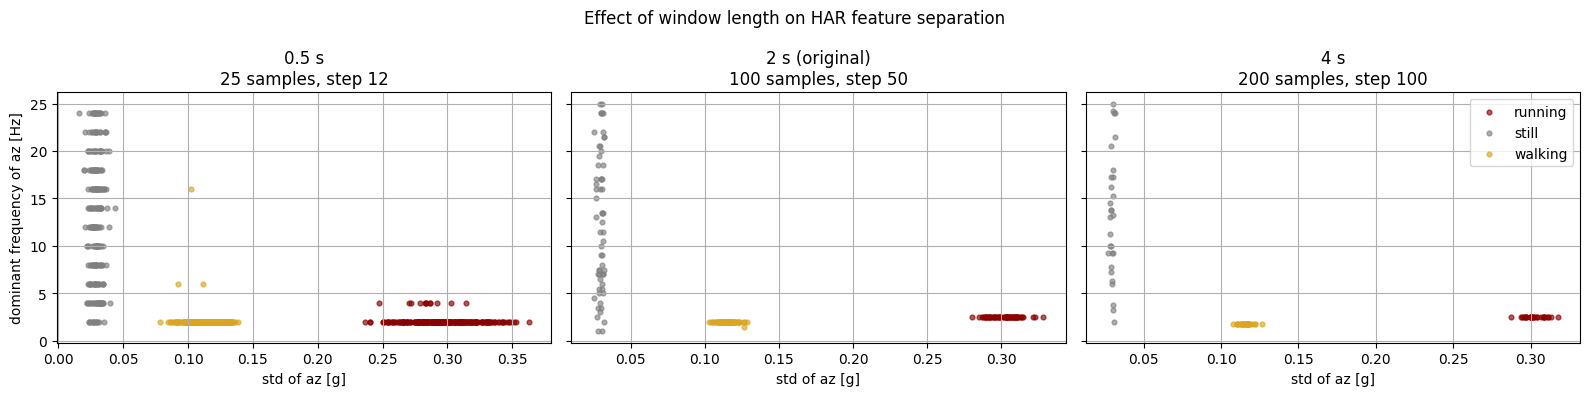

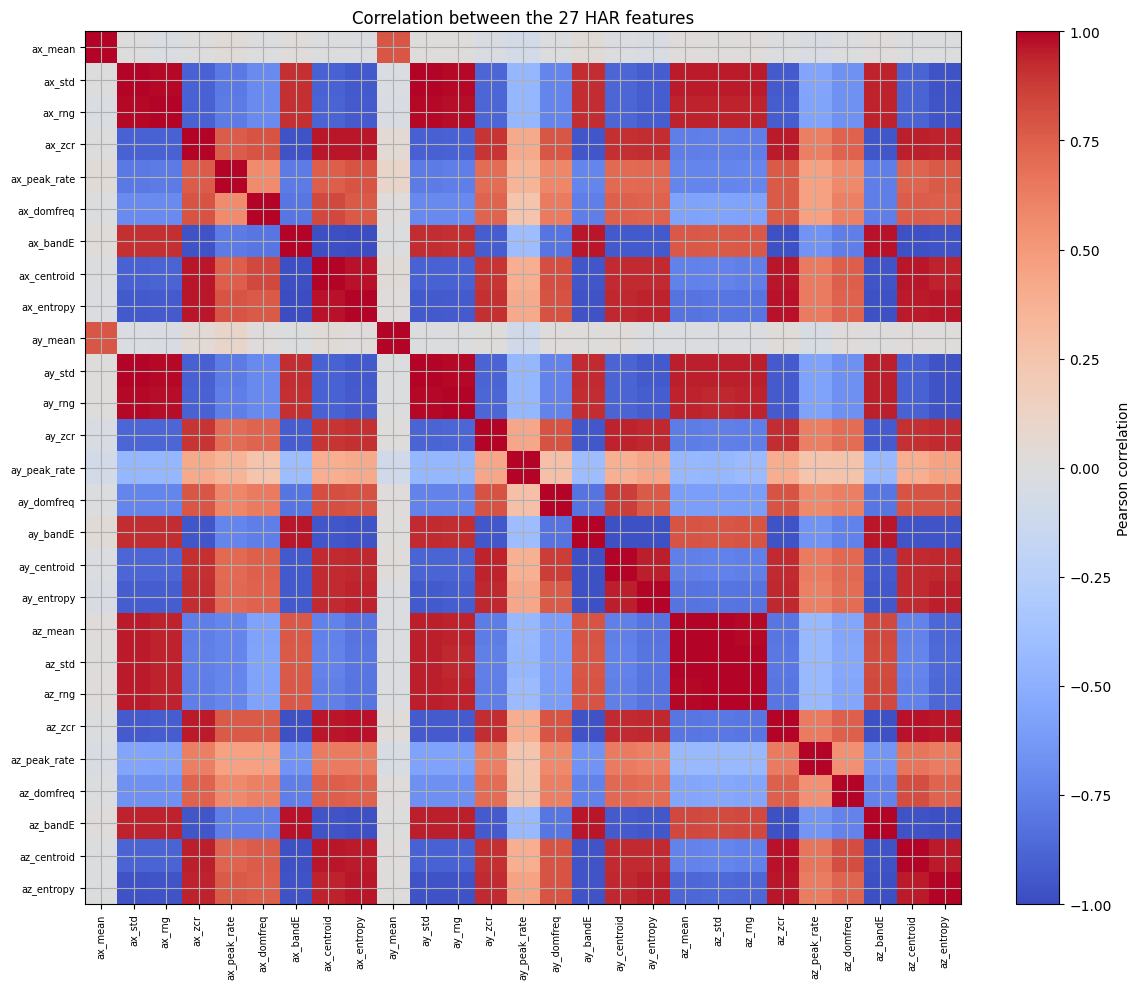

Feature pairs with |correlation| >= 0.95:
az_mean      az_std         0.995190
ax_std       ay_std         0.994501
az_std       az_rng         0.993439
ax_std       ax_rng         0.991409
ay_std       ay_rng         0.991387
az_mean      az_rng         0.989788
ax_bandE     ax_entropy    -0.987627
ax_rng       ay_std         0.987134
ax_std       ay_rng         0.984574
ax_bandE     ax_centroid   -0.983967
az_bandE     az_entropy    -0.983795
ax_rng       ay_rng         0.977294
ay_bandE     ay_entropy    -0.975235
ax_bandE     az_bandE       0.972850
az_zcr       az_bandE      -0.971728
ax_bandE     az_zcr        -0.971315
ax_entropy   az_zcr         0.971086
ay_bandE     ay_centroid   -0.970971
ax_bandE     az_centroid   -0.970870
ax_centroid  ax_entropy     0.969443
az_zcr       az_centroid    0.969298
ax_entropy   az_bandE      -0.968874
az_bandE     az_centroid   -0.968297
ax_zcr       ax_bandE      -0.967770
ax_entropy   az_entropy     0.967268
ay_std       az_entropy    -0.965

In [7]:
# TODO (S1 / S2)

window_settings = {
    "0.5 s": (25, 12),
    "2 s (original)": (100, 50),
    "4 s": (200, 100),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax_, (setting, (win, step)) in zip(axes, window_settings.items()):
    rows_s = []
    for act, df in recordings.items():
        axis_windows = {
            axis: sliding_window(df[axis].to_numpy(), win=win, step=step)
            for axis in ("ax_g", "ay_g", "az_g")
        }
        for i in range(len(axis_windows["az_g"])):
            feats = features_of_window(i, axis_windows)
            rows_s.append(feats | {"label": act})
    har_s = pd.DataFrame(rows_s)
    for act, grp in har_s.groupby("label"):
        ax_.scatter(grp["az_std"], grp["az_domfreq"], s=12, alpha=0.65,
                    color={"still": "grey", "walking": "goldenrod",
                           "running": "darkred"}[act], label=act)
    ax_.set_title(f"{setting}\n{win} samples, step {step}")
    ax_.set_xlabel("std of az [g]")
    ax_.grid(True)
axes[0].set_ylabel("dominant frequency of az [Hz]")
axes[-1].legend()
plt.suptitle("Effect of window length on HAR feature separation")
plt.tight_layout()
plt.show()

# S2 — Inspect feature redundancy with a correlation matrix.
corr = har.drop(columns="label").corr()
plt.figure(figsize=(12, 10))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=7)
plt.title("Correlation between the 27 HAR features")
plt.tight_layout()
plt.show()

# List the strongest non-identical feature pairs.
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = (upper.stack()
                .rename("correlation")
                .loc[lambda s: s.abs() >= 0.95]
                .sort_values(key=np.abs, ascending=False))
print("Feature pairs with |correlation| >= 0.95:")
print(strong_pairs if len(strong_pairs) else "No pairs meet this threshold.")

---
## Before you submit (checklist)

- [ ] Whole notebook runs top to bottom — **Runtime → Restart and run all must pass**
- [ ] Mission 1's checkpoint prints 59 windows of 100
- [ ] Mission 2: all nine questions answer (no `None` left), domfreq ≈ 1.8 on the walking test window
- [ ] Mission 3: `har_features.csv` written, ~177 × 28 (Deliverable 1)
- [ ] Mission 4: the three-island scatter drawn and labelled (Deliverable 2)
- [ ] Q1 and Q2 answered with numbers (Deliverable 3)
- [ ] Pushed to your GitHub repository — **keep har_features.csv safe: weeks 7, 8, 9 and 13 open it**

*Next week: **Data Visualisation** — PCA, t-SNE and UMAP. Today you hand-picked two columns and
hoped for islands; next week the mathematics chooses the view, and all 27 columns become one
picture. Bring this CSV.*
